# Fase 5 — Ajuste fino do BERTimbau


### O que este notebook faz

Carrega o BERTimbau já ajustado, reavalia-o sobre o mesmo conjunto de teste usado na Fase 3 e gera as figuras do treinamento.

### Entradas

- `modelos/bertimbau_final/`
- `dados/corpus_preparado.csv`

### Saídas de dados

- `dados/metricas_bertimbau.csv`
- `dados/predicoes_bertimbau.csv`
- `dados/historico_bertimbau.csv`

### Figuras geradas

- `figuras/fig_curva_treinamento.png`
- `figuras/fig_confusao_bertimbau.png`


## 1. Ambiente

In [1]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

BASE    = Path('/content/drive/MyDrive/TCC')
DADOS   = BASE / 'dados'
FIGURAS = BASE / 'figuras'
MODELOS = BASE / 'modelos'
for pasta in (DADOS, FIGURAS, MODELOS):
    pasta.mkdir(parents=True, exist_ok=True)

print('projeto :', BASE)
print('dados   :', DADOS)
print('figuras :', FIGURAS)
print('modelos :', MODELOS)


Mounted at /content/drive
projeto : /content/drive/MyDrive/TCC
dados   : /content/drive/MyDrive/TCC/dados
figuras : /content/drive/MyDrive/TCC/figuras
modelos : /content/drive/MyDrive/TCC/modelos


## 2. Padrão visual das figuras

In [2]:
%%writefile /content/estilo_sbc.py
# -*- coding: utf-8 -*-
import io
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter, MaxNLocator
from PIL import Image

AZUL    = '#1B4F72'
LARANJA = '#D55E00'
AMBAR   = '#E8B04B'
VERDE   = '#117733'
TEXTO   = '#1A1A1A'
SUAVE   = '#5F6B7A'
GRADE   = '#E4E7EA'
NEUTRO  = '#C3C9D0'

PALETA  = [AZUL, LARANJA, AMBAR, VERDE]

AZUL_TEXTO    = AZUL
LARANJA_TEXTO = '#A64A00'
AMBAR_TEXTO   = '#8A6410'
VERDE_TEXTO   = '#0E5C28'

_LEGIVEL = {AZUL: AZUL_TEXTO, LARANJA: LARANJA_TEXTO,
            AMBAR: AMBAR_TEXTO, VERDE: VERDE_TEXTO}

T_PEQUENO  = 8.0
T_CORPO    = 9.0
T_ROTULO   = 9.5
T_TITULO   = 10.5
T_DESTAQUE = 13.0


def legivel(cor):
    return _LEGIVEL.get(cor, cor)


CORES_MODELO = {
    'Regressao Logistica': AZUL,
    'Regressão Logística': AZUL,
    'Random Forest': LARANJA,
    'BERTimbau': AMBAR,
}
CORES_CLASSE = {'Verdadeira': AZUL, 'Falsa': LARANJA}
MAPA_FRIO = LinearSegmentedColormap.from_list('sbc_frio', ['#F1F4F5', AZUL])
MAPA_DIV  = LinearSegmentedColormap.from_list('sbc_div', [AZUL, '#FFFFFF', LARANJA])


CM = 1 / 2.54
LARGURA = 15 * CM
LARGURA_MEIA = 7.2 * CM

_instaladas = {f.name for f in mpl.font_manager.fontManager.ttflist}
FAMILIA = next((f for f in ('Inter', 'Source Sans 3', 'Lato', 'Open Sans',
                            'Liberation Sans', 'DejaVu Sans')
                if f in _instaladas), 'sans-serif')

mpl.rcParams.update({
    'figure.dpi': 110,
    'savefig.dpi': 400,
    'savefig.bbox': 'tight',
    'savefig.facecolor': 'white',
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',

    'font.family': FAMILIA,
    'font.size': T_CORPO,
    'axes.titlesize': T_TITULO,
    'axes.titleweight': 'bold',
    'axes.titlepad': 12,
    'axes.labelsize': T_CORPO,
    'axes.labelcolor': TEXTO,
    'axes.labelpad': 10,
    'xtick.labelsize': T_CORPO,
    'ytick.labelsize': T_CORPO,
    'legend.fontsize': T_CORPO,

    'text.color': TEXTO,
    'axes.edgecolor': '#B9BDC2',
    'axes.linewidth': 0.8,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.spines.left': False,

    'xtick.color': SUAVE,
    'ytick.color': SUAVE,
    'xtick.direction': 'out',
    'ytick.direction': 'out',
    'xtick.major.size': 0,
    'ytick.major.size': 0,
    'xtick.major.pad': 5,
    'ytick.major.pad': 5,

    'grid.color': GRADE,
    'grid.linewidth': 0.8,
    'axes.grid': False,

    'legend.frameon': False,
    'legend.handlelength': 1.2,
    'legend.handleheight': 1.2,
    'legend.columnspacing': 2.2,
    'legend.borderpad': 0.1,
    'legend.labelspacing': 0.6,

    'axes.prop_cycle': mpl.cycler(color=PALETA),
    'lines.linewidth': 2.0,
    'lines.markersize': 6,
    'patch.linewidth': 0,
})

_destino = Path('.')


def destino(pasta):
    global _destino
    _destino = Path(pasta)
    _destino.mkdir(parents=True, exist_ok=True)
    return _destino


def salvar(fig, nome, largura_cm=15.0, dpi=400):
    caminho = _destino / (nome + '.png')
    if largura_cm is None:
        fig.savefig(caminho, dpi=dpi, bbox_inches='tight', facecolor='white')
        print('[figura]', caminho.name, '(sem normalizacao)')
        return caminho

    alvo = int(round(largura_cm / 2.54 * dpi))
    buf = io.BytesIO()
    fig.savefig(buf, format='png', dpi=dpi, bbox_inches='tight',
                facecolor='white')
    buf.seek(0)
    im = Image.open(buf).convert('RGB')
    nota = ''
    if im.width > alvo:
        fator = alvo / im.width
        im = im.resize((alvo, max(1, int(round(im.height * fator)))),
                       Image.LANCZOS)
        nota = '  (reduzida {:.1%})'.format(1 - fator)
    elif im.width < alvo:
        tela = Image.new('RGB', (alvo, im.height), 'white')
        tela.paste(im, ((alvo - im.width) // 2, 0))
        im = tela
        nota = '  (margem branca completada)'
    im.save(caminho, dpi=(dpi, dpi))
    print('[figura] {:<30} {:.1f} x {:.1f} cm{}'
          .format(caminho.name, largura_cm, im.height / dpi * 2.54, nota))
    return caminho


def br(texto):
    return str(texto).replace(',', '\u0000').replace('.', ',').replace('\u0000', '.')


def pct(valor, dec=1):
    return br(('{:.' + str(dec) + 'f}').format(100 * valor)) + '%'


def mil(valor, dec=0):
    return br(('{:,.' + str(dec) + 'f}').format(valor))


def grade_y(ax, atras=True):
    ax.grid(axis='y', color=GRADE, linewidth=0.8)
    ax.grid(axis='x', visible=False)
    ax.set_axisbelow(atras)
    return ax


def grade_x(ax, atras=True):
    ax.grid(axis='x', color=GRADE, linewidth=0.8)
    ax.grid(axis='y', visible=False)
    ax.set_axisbelow(atras)
    return ax


def sem_grade(ax):
    ax.grid(False)
    for lado in ('top', 'right', 'left', 'bottom'):
        ax.spines[lado].set_visible(False)
    ax.set_xticks([])
    ax.set_yticks([])
    return ax


def eixo_percentual(ax, eixo='y', decimais=0):
    f = FuncFormatter(lambda v, _: pct(v, decimais))
    (ax.yaxis if eixo == 'y' else ax.xaxis).set_major_formatter(f)
    return ax


def eixo_decimal(ax, eixo='y', decimais=2):
    f = FuncFormatter(
        lambda v, _: br(('{:,.' + str(decimais) + 'f}').format(v)))
    (ax.yaxis if eixo == 'y' else ax.xaxis).set_major_formatter(f)
    return ax


def escala_percentual(ax, maximo=1.0, folga_topo=0.20, passo=0.2, decimais=0):
    import numpy as _np
    ax.set_ylim(0, maximo * (1 + folga_topo))
    ax.set_yticks(_np.round(_np.arange(0, maximo + 1e-9, passo), 10))
    eixo_percentual(ax, 'y', decimais)
    return ax


def eixo_milhar(ax, eixo='y'):
    f = FuncFormatter(lambda v, _: mil(v))
    (ax.yaxis if eixo == 'y' else ax.xaxis).set_major_formatter(f)
    return ax


def rotular(ax, barras, fmt='{:.1%}', dy=5, tam=T_ROTULO, peso='bold', cor=None):
    for b in barras:
        v = b.get_height()
        ax.annotate(br(fmt.format(v)),
                    xy=(b.get_x() + b.get_width() / 2, v),
                    xytext=(0, dy), textcoords='offset points',
                    ha='center', va='bottom',
                    fontsize=tam, fontweight=peso,
                    color=cor or TEXTO)
    return ax


def rotular_h(ax, barras, fmt='{:.1%}', dx=6, tam=T_ROTULO, peso='bold', cor=None):
    for b in barras:
        v = b.get_width()
        ax.annotate(br(fmt.format(v)),
                    xy=(v, b.get_y() + b.get_height() / 2),
                    xytext=(dx, 0), textcoords='offset points',
                    ha='left', va='center',
                    fontsize=tam, fontweight=peso,
                    color=cor or TEXTO)
    return ax


def encolher_para_caber(ax, textos, largura_dados, tamanho, minimo=6.5,
                        passo=0.2):
    fig = ax.figure
    fig.canvas.draw()
    renderizador = fig.canvas.get_renderer()
    base = ax.transData.transform((0, 0))[0]
    limite = ax.transData.transform((largura_dados, 0))[0] - base
    while tamanho > minimo:
        maior = max(t.get_window_extent(renderer=renderizador).width
                    for t in textos)
        if maior <= limite:
            break
        tamanho -= passo
        for t in textos:
            t.set_fontsize(tamanho)
    return tamanho


def legenda_abaixo(ax, ncols=2, afastamento=None, **kwargs):
    altura_pt = (ax.get_position().height * ax.figure.get_figheight() * 72) or 1
    if afastamento is None:
        afastamento = -(44 if ax.get_xlabel() else 24) / altura_pt
    return ax.legend(loc='upper center', ncols=ncols,
                     bbox_to_anchor=(0.5, afastamento),
                     fontsize=T_CORPO, **kwargs)


def legenda_manual(ax, itens, ncols=None, **kwargs):
    from matplotlib.patches import Patch
    marcas = [Patch(facecolor=cor, label=rotulo) for rotulo, cor in itens]
    return legenda_abaixo(ax, ncols=ncols or len(itens), handles=marcas,
                          **kwargs)


def titulo(ax, principal, apoio=None):
    linhas_apoio = apoio.count('\n') + 1 if apoio else 0
    ax.set_title(principal, loc='left',
                 pad=(25 + 12 * (linhas_apoio - 1)) if apoio else 10)
    if apoio:
        ax.annotate(apoio, xy=(0, 1), xycoords='axes fraction',
                    xytext=(0, 7), textcoords='offset points',
                    ha='left', va='bottom', fontsize=T_CORPO, color=SUAVE)
    return ax


def espacar(valores, minimo):
    import numpy as _np
    valores = _np.asarray(valores, dtype=float)
    pos = valores.copy()
    ordem = _np.argsort(valores)
    for k in range(1, len(ordem)):
        anterior, atual = ordem[k - 1], ordem[k]
        if pos[atual] - pos[anterior] < minimo:
            pos[atual] = pos[anterior] + minimo
    deslocamento = pos[ordem].mean() - valores[ordem].mean()
    return pos - deslocamento


def folga(ax, eixo='y', fator=0.14):
    if eixo == 'y':
        lo, hi = ax.get_ylim()
        ax.set_ylim(lo, hi + (hi - lo) * fator)
    else:
        lo, hi = ax.get_xlim()
        ax.set_xlim(lo, hi + (hi - lo) * fator)
    return ax


def painel_confusao(ax, matriz, titulo_painel, rotulos=('Verdadeira', 'Falsa'),
                    destaque=None):
    import numpy as np
    matriz = np.asarray(matriz, dtype=float)
    total = matriz.sum()
    ax.imshow(matriz / matriz.max(), cmap=MAPA_FRIO, vmin=0, vmax=1.15)
    for i in range(matriz.shape[0]):
        for j in range(matriz.shape[1]):
            v = matriz[i, j]
            claro = (v / matriz.max()) > 0.55
            ax.text(j, i - 0.10, mil(v),
                    ha='center', va='center', fontsize=T_DESTAQUE,
                    fontweight='bold',
                    color='white' if claro else TEXTO)
            ax.text(j, i + 0.22, pct(v / total, 1),
                    ha='center', va='center', fontsize=T_PEQUENO,
                    color='#E8EEF0' if claro else SUAVE)
    ax.set_xticks([0, 1], ['Predita\n' + rotulos[0], 'Predita\n' + rotulos[1]])
    ax.set_yticks([0, 1], ['Real\n' + rotulos[0], 'Real\n' + rotulos[1]])
    ax.set_title(titulo_painel, loc='center', pad=10,
                 color=legivel(destaque) if destaque else TEXTO)
    for lado in ('top', 'right', 'left', 'bottom'):
        ax.spines[lado].set_visible(False)
    ax.tick_params(length=0)
    ax.grid(False)
    return ax


def barras_pareadas(ax, categorias, series, fmt='{:.1%}', largura_grupo=0.78,
                    rotulo=True):
    import numpy as np
    x = np.arange(len(categorias))
    n = len(series)
    larg = largura_grupo / n
    for k, (nome, valores, cor) in enumerate(series):
        desloc = (k - (n - 1) / 2) * larg
        b = ax.bar(x + desloc, valores, larg * 0.92, label=nome, color=cor)
        if rotulo:
            rotular(ax, b, fmt=fmt, tam=T_PEQUENO)
    ax.set_xticks(x, categorias)
    grade_y(ax)
    return ax


print('estilo_sbc carregado  |  paleta', AZUL, LARANJA, AMBAR)


Writing /content/estilo_sbc.py


In [3]:
import shutil, sys
shutil.copy('/content/estilo_sbc.py', BASE / 'estilo_sbc.py')
sys.path.insert(0, '/content')

from estilo_sbc import *
destino(FIGURAS)

import numpy as np
import pandas as pd


estilo_sbc carregado  |  paleta #1B4F72 #D55E00 #E8B04B


## 3. Localizadores de arquivos e colunas

In [4]:
def arquivo(*nomes):
    tentados = []
    for nome in nomes:
        for pasta in (DADOS, BASE):
            alvo = pasta / nome
            tentados.append(str(alvo))
            if alvo.exists():
                return alvo
    raise FileNotFoundError(
        'Nenhum destes arquivos foi encontrado:\n  ' + '\n  '.join(tentados))


def existe(*nomes):
    try:
        return arquivo(*nomes)
    except FileNotFoundError:
        return None


def coluna(df, *candidatos, obrigatoria=True):
    mapa = {c.strip().lower(): c for c in df.columns}
    for cand in candidatos:
        if cand.strip().lower() in mapa:
            return mapa[cand.strip().lower()]
    for cand in candidatos:
        chave = cand.strip().lower()
        for norm, orig in mapa.items():
            if chave in norm:
                return orig
    if obrigatoria:
        raise KeyError('Nenhuma destas colunas existe: ' + ', '.join(candidatos)
                       + '\nDisponiveis: ' + ', '.join(map(str, df.columns)))
    return None


def csvs_do_projeto():
    achados = []
    for caminho in sorted(BASE.rglob('*.csv')):
        try:
            cabecalho = list(pd.read_csv(caminho, nrows=0).columns)
            with open(caminho, encoding='utf-8', errors='ignore') as fh:
                linhas = max(sum(1 for _ in fh) - 1, 0)
        except Exception as erro:
            cabecalho, linhas = ['<ilegível: {}>'.format(erro)], -1
        achados.append((caminho, linhas, cabecalho))
    return achados


def listar_csvs():
    achados = csvs_do_projeto()
    if not achados:
        print('nenhum CSV encontrado em', BASE)
        return
    for caminho, linhas, colunas in achados:
        print('{:<44} {:>7} linhas   {}'.format(
            str(caminho.relative_to(BASE)), linhas,
            ', '.join(map(str, colunas))[:88]))


def procurar_csv(*pistas_de_coluna, nomes=()):
    if nomes:
        alvo = existe(*nomes)
        if alvo is not None:
            return alvo
    candidatos = []
    for caminho, linhas, colunas in csvs_do_projeto():
        normalizadas = {str(c).strip().lower() for c in colunas}
        if any(any(pista in c for c in normalizadas) for pista in pistas_de_coluna):
            candidatos.append((linhas, caminho))
    if candidatos:
        candidatos.sort(reverse=True)
        escolhido = candidatos[0][1]
        print('localizado pelo conteúdo:', escolhido.relative_to(BASE))
        if len(candidatos) > 1:
            print('outros compatíveis:',
                  [str(c.relative_to(BASE)) for _, c in candidatos[1:]])
        return escolhido
    print('Nenhum CSV com coluna parecida com', pistas_de_coluna, 'foi encontrado.')
    print('Nomes procurados:', nomes or '(nenhum)')
    print('\nCSVs disponíveis em', BASE, ':')
    listar_csvs()
    raise FileNotFoundError(
        'Veja o inventário acima e renomeie o arquivo certo, ou gere-o de novo.')


def modelos_disponiveis():
    import datetime as _dt
    import json as _json
    achados = []
    for config in sorted(BASE.rglob('config.json')):
        pasta = config.parent
        if not (pasta / 'model.safetensors').exists() \
                and not (pasta / 'pytorch_model.bin').exists():
            continue
        marca = pasta / 'convencao_rotulo.json'
        convencao = None
        if marca.exists():
            try:
                convencao = _json.loads(marca.read_text(encoding='utf-8'))
            except Exception:
                convencao = {'erro': 'json ilegivel'}
        achados.append((pasta,
                        _dt.datetime.fromtimestamp(config.stat().st_mtime),
                        convencao))
    return sorted(achados, key=lambda t: t[1], reverse=True)


def listar_modelos():
    achados = modelos_disponiveis()
    if not achados:
        print('nenhum modelo encontrado em', BASE)
        return
    for pasta, quando, convencao in achados:
        print('{:<46} {}  {}'.format(
            str(pasta.relative_to(BASE)), quando.strftime('%d/%m %H:%M'),
            'rótulo 1 = ' + convencao.get('1', '?') if convencao
            else 'SEM convenção declarada'))


def achar_modelo(convencao_exigida='Falsa'):
    disponiveis = [t for t in modelos_disponiveis()
                   if 'checkpoint' not in t[0].name]
    if not disponiveis:
        return None

    corretos = [t for t in disponiveis
                if t[2] and t[2].get('1') == convencao_exigida]
    if corretos:
        return str(corretos[0][0])

    print('AVISO: nenhum modelo declara a convenção "rótulo 1 =',
          convencao_exigida, '". Usando o mais recente; confira a acurácia.')
    listar_modelos()
    return str(disponiveis[0][0])


_NLP = None


def motor_lema():
    global _NLP
    if _NLP is None:
        import spacy
        try:
            _NLP = spacy.load('pt_core_news_sm', disable=['parser', 'ner'])
        except OSError:
            import subprocess, sys
            subprocess.run([sys.executable, '-m', 'spacy', 'download',
                            'pt_core_news_sm'], check=True)
            _NLP = spacy.load('pt_core_news_sm', disable=['parser', 'ner'])
    return _NLP


def lematizar(textos, lote=32):
    nlp = motor_lema()
    return [' '.join(t.lemma_ for t in doc)
            for doc in nlp.pipe(list(textos), batch_size=lote)]


def taxa_de_lema(textos, limite=400):
    nlp = motor_lema()
    iguais = total = 0
    for doc in nlp.pipe(list(textos)[:limite], batch_size=32):
        for t in doc:
            if t.is_alpha and len(t.text) > 2:
                total += 1
                iguais += t.text.lower() == t.lemma_.lower()
    return iguais / total if total else float('nan')


## 4. Chaves de execução


In [5]:
RETREINAR = False
REAVALIAR = True
SEMENTE   = 42

!pip install -q transformers accelerate
import torch
print('GPU disponível:', torch.cuda.is_available(),
      '|', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')


GPU disponível: True | Tesla T4


## 5. Ajuste fino

Três épocas, taxa de aprendizado 2e-5, lotes de 16 e sequências de 256 tokens, que cobrem os primeiros parágrafos — onde está o sinal na maioria dos registros.

São **três** partições, não duas. O teste é o mesmo da Fase 3, para que os modelos sejam comparados sobre as mesmas notícias. A validação sai de dentro do treino, 10% estratificados com semente fixa, e é ela que decide qual época vira o modelo final.

A separação não é formalidade. Com `load_best_model_at_end` apontado para o conjunto de teste, a escolha da época passa a olhar o mesmo conjunto que será reportado depois, e a acurácia final sai otimista por um valor que nenhuma métrica do treino revela. O teste é medido uma única vez, na seção 7, com o modelo já escolhido.

O rótulo vem de `corpus_preparado.csv`, onde a Fase 1 já normalizou 1 como "falsa". O modelo treinado herda essa convenção, e por isso `predito == 1` significa "classificado como falsa" em todas as fases seguintes.

In [6]:
if RETREINAR:
    from sklearn.model_selection import train_test_split
    from transformers import (Trainer, TrainingArguments,
                              DataCollatorWithPadding)
    from sklearn.metrics import accuracy_score, f1_score
    from transformers import AutoTokenizer, AutoModelForSequenceClassification
    import datasets

    df = pd.read_csv(arquivo('corpus_preparado.csv', 'corpus_base.csv')).dropna(subset=['texto'])
    if 'particao' not in df.columns:
        raise ValueError('corpus sem a coluna `particao`. Rode a Fase 1 antes '
                         'desta — é ela que fixa a divisão treino/teste.')
    treino = (df['particao'] == 'treino').to_numpy()
    pos_treino = np.flatnonzero(treino)
    pos_tr, pos_val = train_test_split(
        pos_treino, test_size=0.10, random_state=SEMENTE,
        stratify=df.loc[treino, 'rotulo'].to_numpy())

    textos, rotulos = df['texto'].to_numpy(), df['rotulo'].to_numpy()
    tr_txt, tr_y = textos[pos_tr], rotulos[pos_tr]
    val_txt, val_y = textos[pos_val], rotulos[pos_val]
    te_txt, te_y = df.loc[~treino, 'texto'].values, df.loc[~treino, 'rotulo'].values

    pos_teste = set(np.flatnonzero(~treino))
    if set(pos_tr) & set(pos_val) or (set(pos_tr) | set(pos_val)) & pos_teste:
        raise ValueError('as três partições se sobrepõem — verifique a Fase 1')

    print('treino {} | validação {} | teste {}'.format(
        mil(len(tr_txt)), mil(len(val_txt)), mil(len(te_txt))))
    print('proporção de falsas — treino {} | validação {}'.format(
        pct(tr_y.mean()), pct(val_y.mean())))

    base_tok = AutoTokenizer.from_pretrained('neuralmind/bert-base-portuguese-cased')
    base_mod = AutoModelForSequenceClassification.from_pretrained(
        'neuralmind/bert-base-portuguese-cased', num_labels=2)

    def preparar(textos, rotulos):
        d = datasets.Dataset.from_dict({'text': list(textos),
                                        'labels': list(map(int, rotulos))})
        return d.map(lambda b: base_tok(b['text'], truncation=True, max_length=256),
                     batched=True, remove_columns=['text'])

    def metricas_treino(p):
        pred = p.predictions.argmax(-1)
        return {'accuracy': accuracy_score(p.label_ids, pred),
                'f1': f1_score(p.label_ids, pred)}

    args = TrainingArguments(
        output_dir=str(MODELOS / 'bertimbau_treino'),
        num_train_epochs=3, learning_rate=2e-5,
        per_device_train_batch_size=16, per_device_eval_batch_size=64,
        eval_strategy='epoch', save_strategy='epoch', logging_steps=50,
        load_best_model_at_end=True, metric_for_best_model='f1',
        fp16=torch.cuda.is_available(), seed=SEMENTE, report_to='none')

    treinador = Trainer(model=base_mod, args=args,
                        train_dataset=preparar(tr_txt, tr_y),
                        eval_dataset=preparar(val_txt, val_y),
                        data_collator=DataCollatorWithPadding(base_tok),
                        compute_metrics=metricas_treino)
    treinador.train()
    treinador.save_model(str(MODELOS / 'bertimbau_final'))
    base_tok.save_pretrained(str(MODELOS / 'bertimbau_final'))

    import json as _json
    marca_corpus = existe('corpus_assinatura.json')
    assinatura_corpus = (_json.loads(marca_corpus.read_text(encoding='utf-8'))
                         ['assinatura'] if marca_corpus else None)
    (MODELOS / 'bertimbau_final' / 'convencao_rotulo.json').write_text(
        _json.dumps({'0': 'Verdadeira', '1': 'Falsa',
                     'assinatura_corpus': assinatura_corpus,
                     'treinado_em': pd.Timestamp.now().isoformat(timespec='seconds'),
                     'n_treino': int(len(tr_txt)),
                     'n_validacao': int(len(val_txt)),
                     'epoca_escolhida_por': 'f1 de validação',
                     'teste_visto_no_treino': False,
                     'texto': 'corpo da notícia, sem título'},
                    ensure_ascii=False, indent=1),
        encoding='utf-8')
    print('modelo salvo em', MODELOS / 'bertimbau_final')

    registro = pd.DataFrame(treinador.state.log_history)
    registro.to_csv(DADOS / 'log_treinamento_bruto.csv', index=False)

    avaliacoes = registro[registro['eval_loss'].notna()] \
        if 'eval_loss' in registro.columns else pd.DataFrame()
    treinos = registro[registro['loss'].notna()] \
        if 'loss' in registro.columns else pd.DataFrame()
    linhas = []
    for k, (_, av) in enumerate(avaliacoes.iterrows(), start=1):
        ep = av.get('epoch', k)
        janela = treinos[(treinos['epoch'] > ep - 1)
                         & (treinos['epoch'] <= ep + 1e-6)]['loss']
        linhas.append({'epoca': round(ep),
                       'perda_treino': float(janela.mean()) if len(janela) else np.nan,
                       'perda_validacao': float(av['eval_loss']),
                       'acuracia': float(av.get('eval_accuracy', np.nan)),
                       'f1': float(av.get('eval_f1', np.nan))})
    if linhas:
        pd.DataFrame(linhas).to_csv(DADOS / 'historico_bertimbau.csv', index=False)
        print('histórico de treinamento gravado em dados/historico_bertimbau.csv')
else:
    print('Retreino desligado — usando o modelo já salvo.')


Retreino desligado — usando o modelo já salvo.


## 6. Carregamento do modelo


In [7]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

print('modelos disponíveis no projeto:')
listar_modelos()
print()

CAMINHO_MODELO = achar_modelo(convencao_exigida='Falsa')
print('modelo escolhido:', CAMINHO_MODELO)
if CAMINHO_MODELO is None:
    raise FileNotFoundError(
        'Nenhuma pasta com config.json foi encontrada em ' + str(BASE) +
        '. Rode a célula anterior com RETREINAR = True.')

tok = AutoTokenizer.from_pretrained(CAMINHO_MODELO)
modelo = AutoModelForSequenceClassification.from_pretrained(CAMINHO_MODELO)
modelo.eval()
dispositivo = 'cuda' if torch.cuda.is_available() else 'cpu'
modelo.to(dispositivo)
print('parâmetros:', mil(sum(p.numel() for p in modelo.parameters())))


modelos disponíveis no projeto:
modelos/bertimbau_final                        17/10 17:16  rótulo 1 = Falsa
modelos/bertimbau_treino/checkpoint-1608       17/10 17:14  SEM convenção declarada
modelos/bertimbau_treino/checkpoint-1072       17/10 17:11  SEM convenção declarada
modelos/bertimbau_treino/checkpoint-536        17/10 17:08  SEM convenção declarada
modelos/bertimbau_treino/checkpoint-1788       16/10 16:48  SEM convenção declarada
modelos/bertimbau_treino/checkpoint-1192       16/10 16:46  SEM convenção declarada
modelos/bertimbau_treino/checkpoint-596        16/10 16:44  SEM convenção declarada
modelos/modelo_bertimbau_final                 02/10 14:18  SEM convenção declarada

modelo escolhido: /content/drive/MyDrive/TCC/modelos/bertimbau_final


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

parâmetros: 108.924.674


## 7. Reavaliação sobre o conjunto de teste

A divisão é refeita com a mesma semente e a mesma estratificação da Fase 3, de modo que os três modelos sejam comparados sobre exatamente as mesmas notícias. Sem isso, qualquer diferença de acurácia poderia vir da divisão, não do modelo.

In [8]:
import json as _json
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

df = pd.read_csv(arquivo('corpus_preparado.csv', 'corpus_base.csv')).dropna(subset=['texto'])
if 'particao' not in df.columns:
    raise ValueError('corpus sem a coluna `particao`. Rode a Fase 1 antes desta.')
teste = (df['particao'] == 'teste').to_numpy()
te_txt, te_y = df.loc[teste, 'texto'].values, df.loc[teste, 'rotulo'].values
print('conjunto de teste:', mil(len(te_txt)), 'notícias')

marca = Path(CAMINHO_MODELO) / 'convencao_rotulo.json'
marca_corpus = existe('corpus_assinatura.json')
if marca.exists() and marca_corpus is not None:
    do_modelo = _json.loads(marca.read_text(encoding='utf-8'))
    do_corpus = _json.loads(marca_corpus.read_text(encoding='utf-8'))
    if do_modelo.get('assinatura_corpus') != do_corpus.get('assinatura'):
        raise ValueError(
            'O modelo foi treinado sobre outra versão do corpus '
            '(assinatura {} contra {} do corpus atual). Rode a Fase 1, a 2 e '
            'então a Fase 5 com RETREINAR = True, nesta ordem.'
            .format(do_modelo.get('assinatura_corpus'), do_corpus.get('assinatura')))
    print('assinatura do corpus confere:', do_corpus.get('assinatura'))
else:
    print('AVISO: modelo ou corpus sem assinatura. Não há como confirmar que '
          'foram treinados juntos — confira a acurácia abaixo com atenção.')

if REAVALIAR:
    @torch.no_grad()
    def prever(textos, lote=64):
        saidas = []
        for i in range(0, len(textos), lote):
            bloco = [str(t) for t in textos[i:i + lote]]
            ent = tok(bloco, truncation=True, max_length=256,
                      padding=True, return_tensors='pt').to(dispositivo)
            saidas.append(modelo(**ent).logits.argmax(-1).cpu().numpy())
            if (i // lote) % 10 == 0:
                print('  {:>5}/{}'.format(i, len(textos)), end='\r')
        return np.concatenate(saidas)

    pred_bert = prever(te_txt)
    pd.DataFrame({'y_verdadeiro': te_y, 'BERTimbau': pred_bert}).to_csv(
        DADOS / 'predicoes_bertimbau.csv', index=False)
else:
    tabela = pd.read_csv(arquivo('predicoes_bertimbau.csv'))
    te_y, pred_bert = tabela['y_verdadeiro'].values, tabela['BERTimbau'].values

acerto = accuracy_score(te_y, pred_bert)
if acerto < 0.5:
    print(confusion_matrix(te_y, pred_bert, labels=[0, 1]))
    raise ValueError(
        'O modelo acertou {} do conjunto de teste — abaixo do acaso, com a '
        'matriz quase toda na anti-diagonal. Erro de modelo é ruidoso; '
        'inversão exata como esta é erro de gabarito. Quer dizer que o '
        'modelo aprendeu a codificação de rótulo oposta à do corpus atual, '
        'quase sempre porque foi treinado antes de a Fase 1 regravar os '
        'rótulos. Rode a Fase 1, depois a 2, e só então a Fase 5 com '
        'RETREINAR = True.'.format(pct(acerto, 2)))

metricas_bert = pd.DataFrame([{
    'modelo': 'BERTimbau',
    'acuracia': accuracy_score(te_y, pred_bert),
    'precisao': precision_score(te_y, pred_bert),
    'revocacao': recall_score(te_y, pred_bert),
    'f1': f1_score(te_y, pred_bert),
    'erros': int((pred_bert != te_y).sum()),
    'n_teste': len(te_y),
}]).set_index('modelo')
metricas_bert.to_csv(DADOS / 'metricas_bertimbau.csv')

print(classification_report(te_y, pred_bert,
                            target_names=['Verdadeira', 'Falsa'], digits=4))
print(confusion_matrix(te_y, pred_bert))


conjunto de teste: 2.381 notícias
assinatura do corpus confere: e809ede38508
              precision    recall  f1-score   support

  Verdadeira     0.9787    0.9664    0.9725      1191
       Falsa     0.9668    0.9790    0.9729      1190

    accuracy                         0.9727      2381
   macro avg     0.9728    0.9727    0.9727      2381
weighted avg     0.9728    0.9727    0.9727      2381

[[1151   40]
 [  25 1165]]


## 8. Histórico de treinamento

Os valores por época não são redigitados: são lidos do `trainer_state.json` que o `Trainer` grava junto dos checkpoints. É a própria saída do treinamento, com o registro exato de perda e métricas. Se nenhum estado for encontrado, a célula avisa e segue sem a figura de curva, em vez de inventar números.

In [9]:
import json as _json

def historico_do_trainer(raiz):
    estados = sorted(raiz.rglob('trainer_state.json'))
    if not estados:
        return None, None
    def tamanho(p):
        try:
            return len(_json.loads(p.read_text())['log_history'])
        except Exception:
            return -1
    melhor = max(estados, key=tamanho)
    if tamanho(melhor) <= 0:
        return None, None
    log = _json.loads(melhor.read_text())['log_history']

    avaliacoes = [r for r in log if 'eval_loss' in r]
    treinos    = [r for r in log if 'loss' in r and 'eval_loss' not in r]
    linhas = []
    for k, av in enumerate(avaliacoes, start=1):
        ep = av.get('epoch', k)
        janela = [r['loss'] for r in treinos if ep - 1 < r.get('epoch', 0) <= ep + 1e-6]
        linhas.append({
            'epoca': round(ep),
            'perda_treino': float(np.mean(janela)) if janela else np.nan,
            'perda_validacao': av['eval_loss'],
            'acuracia': av.get('eval_accuracy', np.nan),
            'f1': av.get('eval_f1', np.nan),
        })
    return pd.DataFrame(linhas), melhor

pronto = existe('historico_bertimbau.csv')
if pronto is not None:
    historico, origem = pd.read_csv(pronto), pronto
else:
    historico, origem = historico_do_trainer(BASE)
if historico is None:
    print('ATENÇÃO: nenhum trainer_state.json nem historico_bertimbau.csv '
          'encontrado.\nA figura de curva de treinamento será pulada. Para '
          'gerá-la, preserve a pasta de checkpoints do treino ou grave o '
          'histórico em dados/historico_bertimbau.csv com as colunas '
          'epoca, perda_treino, perda_validacao, acuracia, f1.')
else:
    historico.to_csv(DADOS / 'historico_bertimbau.csv', index=False)
    print('histórico lido de:', origem)
    print(historico.round(4).to_string(index=False))


histórico lido de: /content/drive/MyDrive/TCC/dados/historico_bertimbau.csv
 epoca  perda_treino  perda_validacao  acuracia     f1
     1        0.2097           0.1218    0.9643 0.9644
     2        0.0841           0.1338    0.9685 0.9687
     3        0.0299           0.1418    0.9738 0.9738


## 9. Figura — curva de treinamento

Dois painéis empilhados em vez de dois eixos verticais no mesmo gráfico. Perda e F1 têm escalas e sentidos opostos; sobrepô-los num eixo duplo permitiria escolher escalas que sugerem qualquer correlação desejada. Empilhados, compartilham o eixo de épocas e cada escala permanece honesta. O losango marca a época escolhida — a de maior F1, não a de menor perda de validação, que não é monotônica.

/content/estilo_sbc.py:133: UserWarning: Glyph 9671 (\N{WHITE DIAMOND}) missing from font(s) Liberation Sans.
  fig.savefig(buf, format='png', dpi=dpi, bbox_inches='tight',


[figura] fig_curva_treinamento.png      15.0 x 10.3 cm  (margem branca completada)


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9671 (\N{WHITE DIAMOND}) missing from font(s) Liberation Sans.
  fig.canvas.print_figure(bytes_io, **kw)


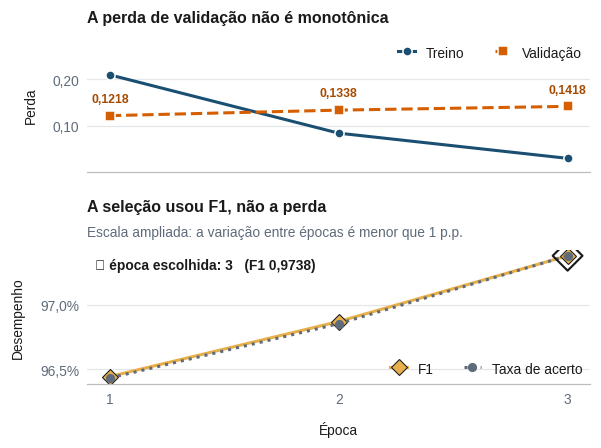

In [10]:
if historico is not None:
    h = historico.sort_values('epoca')
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(LARGURA, 10.4 * CM),
                                 sharex=True, height_ratios=[1, 1],
                                 gridspec_kw={'hspace': 0.58})

    a1.plot(h['epoca'], h['perda_treino'], '-o', color=AZUL,
            label='Treino', markeredgecolor='white', markeredgewidth=1.0)
    a1.plot(h['epoca'], h['perda_validacao'], '--s', color=LARANJA,
            label='Validação', markeredgecolor='white', markeredgewidth=1.0)
    for x, y in zip(h['epoca'], h['perda_validacao']):
        a1.annotate(br('{:.4f}'.format(y)), (x, y), xytext=(0, 9),
                    textcoords='offset points', ha='center',
                    fontsize=T_PEQUENO, color=LARANJA_TEXTO, fontweight='bold')
    grade_y(a1)
    eixo_decimal(a1, 'y', 2)
    a1.margins(y=0.16)
    a1.set_ylabel('Perda')
    a1.legend(loc='upper right', ncols=2)
    folga(a1, 'y', 0.22)
    titulo(a1, 'A perda de validação não é monotônica')

    a2.plot(h['epoca'], h['f1'], '-D', color=AMBAR, markersize=7,
            markeredgecolor=TEXTO, markeredgewidth=0.7, label='F1')
    if h['acuracia'].notna().any():
        a2.plot(h['epoca'], h['acuracia'], ':o', color=SUAVE,
                markersize=5, label='Taxa de acerto')
    melhor = h.loc[h['f1'].idxmax()]
    a2.scatter([melhor['epoca']], [melhor['f1']], s=190, marker='D',
               facecolor='none', edgecolor=TEXTO, linewidth=1.4, zorder=5)
    a2.annotate('◇ época escolhida: {:.0f}   (F1 {})'
                .format(melhor['epoca'], br('{:.4f}'.format(melhor['f1']))),
                xy=(0.015, 0.94), xycoords='axes fraction',
                ha='left', va='top',
                fontsize=T_CORPO, fontweight='bold', color=TEXTO)
    grade_y(a2)
    eixo_percentual(a2, 'y', 1)
    a2.set_ylabel('Desempenho')
    a2.set_xlabel('Época')
    a2.set_xticks(h['epoca'].astype(int))
    a2.legend(loc='lower right', ncols=2)
    titulo(a2, 'A seleção usou F1, não a perda',
           'Escala ampliada: a variação entre épocas é menor que 1 p.p.')

    salvar(fig, 'fig_curva_treinamento')
    plt.show()
else:
    print('figura pulada: histórico indisponível')


## 10. Figura — matriz de confusão do BERTimbau


[figura] fig_confusao_bertimbau.png     9.0 x 8.3 cm  (margem branca completada)


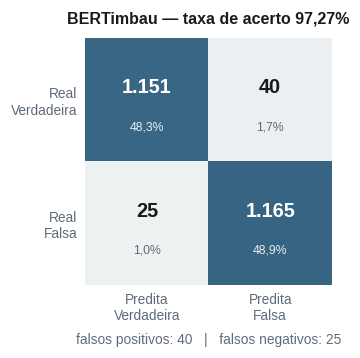

erro total: 65 de 2381 (2.73%)


In [11]:
m = confusion_matrix(te_y, pred_bert, labels=[0, 1])
fig, ax = plt.subplots(figsize=(9.0 * CM, 7.4 * CM))
painel_confusao(ax, m, 'BERTimbau — taxa de acerto ' + pct(m.trace() / m.sum(), 2))
falso_pos, falso_neg = int(m[0, 1]), int(m[1, 0])
ax.annotate('falsos positivos: {}   |   falsos negativos: {}'
            .format(falso_pos, falso_neg),
            xy=(0.5, -0.24), xycoords='axes fraction', ha='center',
            fontsize=T_CORPO, color=SUAVE)
salvar(fig, 'fig_confusao_bertimbau', largura_cm=9.0)
plt.show()

print('erro total: {} de {} ({:.2%})'.format(int(m.sum() - m.trace()),
                                             int(m.sum()),
                                             1 - m.trace() / m.sum()))
